# Quickstart: Google WeatherNext 3 forecasts, virtual - dynamical.org Icechunk Zarr

WeatherNext 3 provides precomputed ensemble statistics for two forecast horizons and two output heads, with a 2026 archive and ongoing updates. The 15-day products initialize every six hours with hourly leads through +360 h; the 48-hour products initialize hourly with leads through +48 h.

The 0.1° head contains gridded surface weather fields. The 0.05° head provides station-trained temperature and dewpoint, evaluated globally: it is neither a resampling of the 0.1° fields nor station observations.

Dataset documentation:
- Google WeatherNext 3 forecast, 15 day, 0.1 degree, virtual: https://dynamical.org/catalog/google-weathernext3-forecast-15-day-0-1-degree-virtual/
- Google WeatherNext 3 forecast, 15 day, 0.05 degree, virtual: https://dynamical.org/catalog/google-weathernext3-forecast-15-day-0-05-degree-virtual/
- Google WeatherNext 3 forecast, 48 hour, 0.1 degree, virtual: https://dynamical.org/catalog/google-weathernext3-forecast-48-hour-0-1-degree-virtual/
- Google WeatherNext 3 forecast, 48 hour, 0.05 degree, virtual: https://dynamical.org/catalog/google-weathernext3-forecast-48-hour-0-05-degree-virtual/

Real-time data and forecasts are subject to Google's [GDM Real-Time Weather Forecasting Experimental Data Terms of Use](https://storage.googleapis.com/weathernext-public/terms-of-use.pdf); historical data are licensed [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Retain the dataset attribution and [third-party acknowledgements](https://storage.googleapis.com/weathernext-public/weathernext-3-attributions-acknowledgements.pdf).

In [ ]:
# If running locally, follow README.md for simple dependency installation.
# If using Google Colab, run this cell.
!uv pip install 'dynamical-catalog>=1.0.1' 'gribberish>=1.8.4' cartopy rioxarray

In [2]:
import dynamical_catalog

forecast_15d_01 = dynamical_catalog.open(
    "google-weathernext3-forecast-15-day-0-1-degree-virtual", chunks=None
)
forecast_15d_005 = dynamical_catalog.open(
    "google-weathernext3-forecast-15-day-0-05-degree-virtual", chunks=None
)
forecast_48h_01 = dynamical_catalog.open(
    "google-weathernext3-forecast-48-hour-0-1-degree-virtual", chunks=None
)
forecast_48h_005 = dynamical_catalog.open(
    "google-weathernext3-forecast-48-hour-0-05-degree-virtual", chunks=None
)
forecast_15d_01

<xarray.Dataset> Size: 1PB
Dimensions:                                            (init_time: 1227,
                                                        statistic: 6,
                                                        lead_time: 360,
                                                        y: 1801, x: 3600)
Coordinates:
  * init_time                                          (init_time) datetime64[ns] 10kB ...
    expected_forecast_length                           (init_time) timedelta64[us] 10kB ...
  * statistic                                          (statistic) StringDType() 96B ...
  * lead_time                                          (lead_time) timedelta64[us] 3kB ...
    valid_time                                         (init_time, lead_time) datetime64[ns] 4MB ...
  * y                                                  (y) float64 14kB -90.0...
  * x                                                  (x) float64 29kB 0.0 ....
    spatial_ref                                        int64 8B ...
Data variables: (12/19)
    cloud_cover_high                                   (init_time, statistic, lead_time, y, x) float32 69TB ...
    cloud_cover_medium                                 (init_time, statistic, lead_time, y, x) float32 69TB ...
    cloud_cover_low                                    (init_time, statistic, lead_time, y, x) float32 69TB ...
    dew_point_temperature_2m                           (init_time, statistic, lead_time, y, x) float32 69TB ...
    downward_direct_short_wave_radiation_flux_surface  (init_time, statistic, lead_time, y, x) float32 69TB ...
    precipitation_experimental_surface                 (init_time, statistic, lead_time, y, x) float32 69TB ...
    ...                                                 ...
    wind_u_10m                                         (init_time, statistic, lead_time, y, x) float32 69TB ...
    sea_surface_temperature                            (init_time, statistic, lead_time, y, x) float32 69TB ...
    wind_speed_100m                                    (init_time, statistic, lead_time, y, x) float32 69TB ...
    precipitation_imerg_surface                        (init_time, statistic, lead_time, y, x) float32 69TB ...
    wind_v_100m                                        (init_time, statistic, lead_time, y, x) float32 69TB ...
    wind_v_10m                                         (init_time, statistic, lead_time, y, x) float32 69TB ...
Attributes:
    dataset_id:           google-weathernext3-forecast-15-day-0-1-degree-virtual
    dataset_version:      0.1.0
    name:                 Google WeatherNext 3 forecast, 15 day, 0.1 degree, ...
    description:          Weather forecasts from the 64-member Google DeepMin...
    attribution:          Google WeatherNext 3 forecast data processed by dyn...
    license:              Real-Time Data & Forecasts: GDM Real-Time Weather F...
    spatial_domain:       Global
    spatial_resolution:   0.1 degrees (~10km)
    time_domain:          Forecasts initialized 2026-01-01 00:00:00 UTC to Pr...
    time_resolution:      Forecasts initialized every 6 hours
    forecast_domain:      Forecast lead time 1-360 hours ahead
    forecast_resolution:  Hourly

## What does an hourly temperature forecast look like?

Follow the 0.05° station-trained forecast near Zurich through 1 July 2026, using the 05 UTC initialization. The precomputed p10, median (p50), and p90 describe the ensemble distribution at each hour; they are not individual member trajectories.

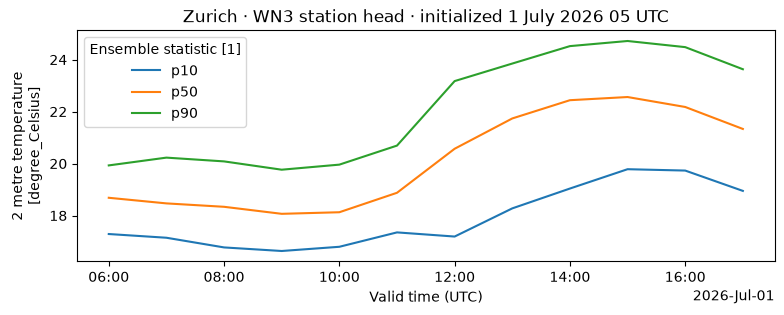

In [3]:
import matplotlib.pyplot as plt
import pandas as pd

zurich = (
    forecast_48h_005["temperature_2m"]
    .sel(
        init_time="2026-07-01T05",
        lead_time=slice(pd.Timedelta("1h"), pd.Timedelta("12h")),
        statistic=["p10", "p50", "p90"],
    )
    .sel(y=47.38, x=8.54, method="nearest")
    .load()
)
zurich.plot.line(x="valid_time", hue="statistic", figsize=(9, 3))
plt.title("Zurich · WN3 station head · initialized 1 July 2026 05 UTC")
plt.xlabel("Valid time (UTC)");

## How do WeatherNext 2 and 3 represent Alpine temperatures?

Google's [WeatherNext 3 paper, Figure A.13](https://arxiv.org/html/2609.03582v1#A3.F13), illustrates the Alpine station head with the 1 July 2026 00 UTC run at +24 hours. Here the WN2 ensemble mean and both WN3 heads share that initialization and valid time, with each shown on its native grid; the 0.05° head changes the training target as well as the resolution, so these differences are not a test of forecast skill.

In [4]:
forecast_wn2 = dynamical_catalog.open(
    "google-weathernext2-forecast-operational-virtual", chunks=None
)
alpine_selection = {
    "init_time": "2026-07-01T00",
    "lead_time": "24h",
    "y": slice(43, 49),
    "x": slice(4, 17),
}
alpine_wn2 = (
    forecast_wn2["temperature_2m"]
    .sel(**alpine_selection)
    .load()
    .mean("ensemble_member", skipna=False, keep_attrs=True)
)
alpine_wn3 = {
    label: ds["temperature_2m"].sel(**alpine_selection, statistic="mean").load()
    for label, ds in [
        ("WN3 · 0.1° surface head", forecast_15d_01),
        ("WN3 · 0.05° station head", forecast_15d_005),
    ]
}

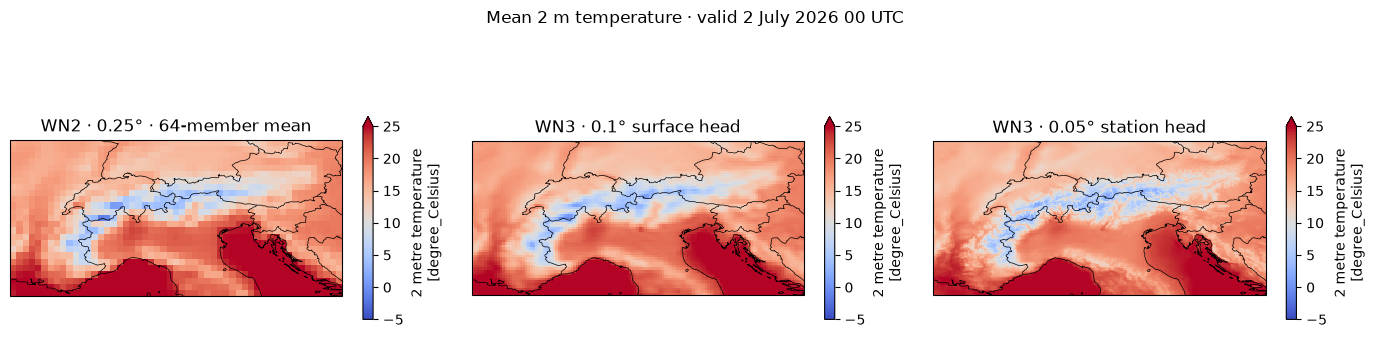

In [5]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature

fig, axes = plt.subplots(
    1, 3, figsize=(14, 4), subplot_kw={"projection": ccrs.PlateCarree()}
)
for ax, (label, temperature) in zip(
    axes, {"WN2 · 0.25° · 64-member mean": alpine_wn2, **alpine_wn3}.items()
):
    temperature.plot.pcolormesh(
        ax=ax,
        x="x",
        y="y",
        transform=ccrs.PlateCarree(),
        cmap="coolwarm",
        vmin=-5,
        vmax=25,
        center=False,
        cbar_kwargs={"shrink": 0.6},
    )
    ax.coastlines(linewidth=0.5)
    ax.add_feature(cfeature.BORDERS, linewidth=0.5)
    ax.set_title(label)
fig.suptitle("Mean 2 m temperature · valid 2 July 2026 00 UTC")
fig.tight_layout()

## Where does the forecast place Gujarat's monsoon rain?

[IMD reported exceptionally heavy rainfall in Gujarat](https://internal.imd.gov.in/press_release/20260724_pr_5181.pdf) in the 24 hours ending 24 July 2026 at 03 UTC. Animate WN3's IMERG-trained precipitation forecast from the 23 July 03 UTC initialization over that window: each frame shows an ensemble-mean hourly rate, not an observed rainfall map.

In [6]:
rain = (
    forecast_48h_01["precipitation_imerg_surface"]
    .sel(
        init_time="2026-07-23T03",
        lead_time=slice(pd.Timedelta("1h"), pd.Timedelta("24h")),
        statistic="mean",
        y=slice(18, 27),
        x=slice(67, 78),
    )
    .load()
    * 3600
)
rain.attrs = {"long_name": "IMERG-head mean precipitation rate", "units": "mm h-1"}

In [7]:
from IPython.display import HTML
from matplotlib.animation import FuncAnimation
from matplotlib.collections import QuadMesh

fig, ax = plt.subplots(
    figsize=(6, 4.5), dpi=80, subplot_kw={"projection": ccrs.PlateCarree()}
)
mesh = rain.isel(lead_time=0).plot.pcolormesh(
    ax=ax,
    x="x",
    y="y",
    transform=ccrs.PlateCarree(),
    cmap="Blues",
    vmin=0,
    vmax=10,
)
ax.coastlines(linewidth=0.5)
ax.add_feature(cfeature.BORDERS, linewidth=0.5)


def update(frame: int) -> tuple[QuadMesh]:
    field = rain.isel(lead_time=frame)
    mesh.set_array(field.values.ravel())
    valid_time = field.valid_time.dt.strftime("%d %b %H:%M UTC").item()
    ax.set_title(f"WN3 IMERG-head mean rain rate\nHour ending {valid_time}")
    return (mesh,)


anim = FuncAnimation(fig, update, frames=rain.sizes["lead_time"], interval=250)
plt.close(fig)
HTML(anim.to_jshtml())

## Community challenge

- Do the station-head temperature percentiles contain the expected fraction of independent station observations, and does that change with terrain or lead time?
- At matched initialization and valid times, how do WN2 and the two WN3 temperature heads compare against observations after accounting for their different grids?
- How do WN3's IMERG-trained and experimental satellite-radar precipitation heads differ during the Gujarat event, and how do their hourly mean rates compare with observed rainfall over matching intervals?